<a href="https://colab.research.google.com/github/code-ajay-17/power_consumption_DL/blob/main/Electricity_consumption.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully!")

All libraries imported successfully!


In [32]:
import os
import glob

files_found = glob.glob(
    "/content/**/*.csv", recursive=True
)

files_found += glob.glob(
    "/content/drive/**/*.csv", recursive=True
)

files_found = list(set(files_found))

print("CSV files found:")
for f in files_found:
    print(f)

CSV files found:
/content/household_power_consumption.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv


In [33]:
import pandas as pd

matches = [
    f for f in files_found
    if "household_power_consumption" in os.path.basename(f).lower()
]

if matches:
    file_path = matches[0]
    df = pd.read_csv(file_path, na_values="?")
    print("Dataset loaded successfully!")
    print("File:", file_path)
    print("Shape:", df.shape)
    display(df.head())
else:
    print("CSV not found. Please upload it again in Colab.")

Dataset loaded successfully!
File: /content/household_power_consumption.csv
Shape: (1048575, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [ ]:
print("Columns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())

Columns: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

Missing values:
Date                        0
Time                        0
Global_active_power      3937
Global_reactive_power    3937
Voltage                  3937
Global_intensity         3937
Sub_metering_1           3937
Sub_metering_2           3937
Sub_metering_3           3937
dtype: int64


In [ ]:
df.columns = df.columns.str.strip()

if "Date" in df.columns and "Time" in df.columns:
    df["datetime"] = pd.to_datetime(
        df["Date"].astype(str) + " " + df["Time"].astype(str),
        dayfirst=True, errors="coerce"
    )
    df = df.drop(columns=["Date", "Time"])
    df = df.dropna(subset=["datetime"])
    df = df.sort_values("datetime")
    df = df.drop_duplicates("datetime")
    df = df.set_index("datetime")

for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)

print("Cleaning completed!")

Cleaning completed!


In [ ]:
df = df.interpolate(method="time", limit_direction="both")
df = df.dropna()

print("Missing values:", df.isnull().sum().sum())
print("Available records:", len(df))

Missing values: 0
Available records: 579962


In [35]:
target_col = "Global_active_power"

if target_col not in df.columns:
    raise ValueError(f"Target column not found. Columns: {df.columns.tolist()}")

data = df.select_dtypes(include=np.number).iloc[:10000].copy()

if len(data) < 10000:
    raise ValueError(f"Only {len(data)} records available.")

print("Selected records:", len(data))
display(data.head())

Selected records: 10000


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,3.666,0.528,235.68,15.8,0.0,1.0,17.0


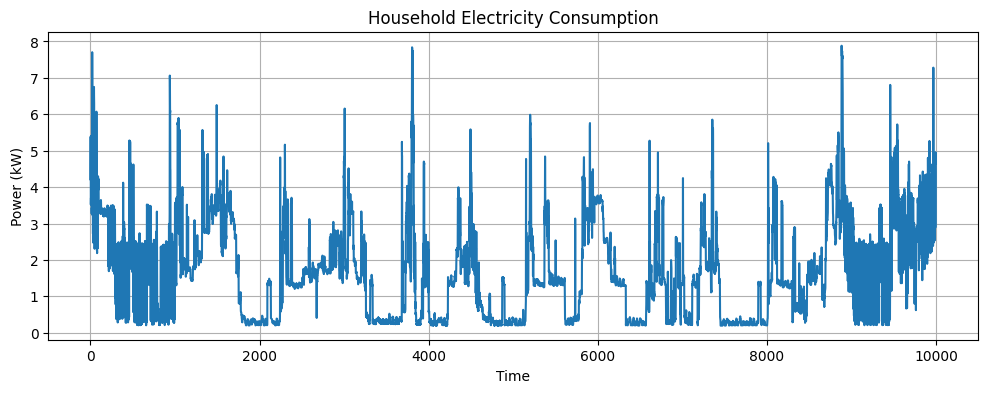

In [36]:
plt.figure(figsize=(12, 4))
plt.plot(data.index, data[target_col])
plt.title("Household Electricity Consumption")
plt.xlabel("Time")
plt.ylabel("Power (kW)")
plt.grid()
plt.show()

Start date: 2007-12-13 21:38:00
End date: 2008-12-13 21:38:00
Records: 526906


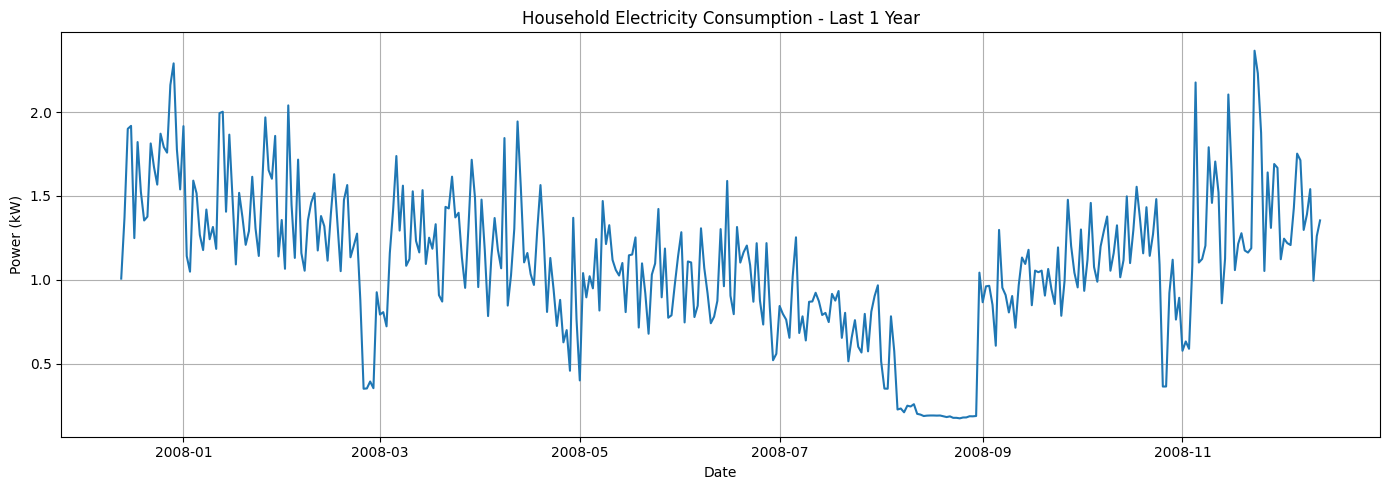

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

target_col = "Global_active_power"

# Convert Date and Time into datetime
df["datetime"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    dayfirst=True,
    errors="coerce"
)

# Sort data by date
df = df.dropna(subset=["datetime"]).sort_values("datetime")
df[target_col] = pd.to_numeric(df[target_col], errors="coerce")

# Select last 1 year from available data
end_date = df["datetime"].max()
start_date = end_date - pd.DateOffset(years=1)

year_data = df[
    (df["datetime"] >= start_date) &
    (df["datetime"] <= end_date)
].copy()

year_data = year_data.dropna(subset=[target_col])

print("Start date:", year_data["datetime"].min())
print("End date:", year_data["datetime"].max())
print("Records:", len(year_data))

# Plot daily average for a clearer yearly graph
daily_data = year_data.set_index("datetime")[target_col].resample("D").mean()

plt.figure(figsize=(14, 5))
plt.plot(daily_data.index, daily_data.values)
plt.title("Household Electricity Consumption - Last 1 Year")
plt.xlabel("Date")
plt.ylabel("Power (kW)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
features = data.columns.tolist()
split = int(len(data) * 0.8)

feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

feature_scaler.fit(data.iloc[:split])
target_scaler.fit(data.iloc[:split][[target_col]])

scaled_features = feature_scaler.transform(data)
scaled_target = target_scaler.transform(data[[target_col]])

print("Normalization completed!")
print("Training records:", split)
print("Testing records:", len(data) - split)

Normalization completed!
Training records: 8000
Testing records: 2000


In [ ]:
LOOKBACK = 60

X_train, y_train = [], []
X_test, y_test = [], []

for i in range(LOOKBACK, split):
    X_train.append(scaled_features[i-LOOKBACK:i])
    y_train.append(scaled_target[i, 0])

for i in range(split, len(data)):
    X_test.append(scaled_features[i-LOOKBACK:i])
    y_test.append(scaled_target[i, 0])

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (7940, 60, 7)
X_test: (2000, 60, 7)


In [ ]:
model = Sequential([
    LSTM(64, input_shape=(LOOKBACK, len(features))),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,545 (80.25 KB)

 Trainable params: 20,545 (80.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop]
)

print("Training completed!")

Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - loss: 0.0142 - val_loss: 0.0020
Epoch 2/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - loss: 0.0057 - val_loss: 0.0017
Epoch 3/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 81ms/step - loss: 0.0048 - val_loss: 0.0015
Epoch 4/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - loss: 0.0044 - val_loss: 0.0014
Epoch 5/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 8s 67ms/step - loss: 0.0043 - val_loss: 0.0016
Epoch 6/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - loss: 0.0041 - val_loss: 0.0015
Epoch 7/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - loss: 0.0040 - val_loss: 0.0013
Epoch 8/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - loss: 0.0040 - val_loss: 0.0013
Epoch 9/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - loss: 0.0039 - val_loss: 0.0012
Epoch 10/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - loss: 0.0039 - val_loss: 0.0013
Epoch 11/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - loss: 0.0038 - val_loss: 0.0011
Epoch 12/15
112/112 ━━━━━━━━━━━━━━━━━━━━

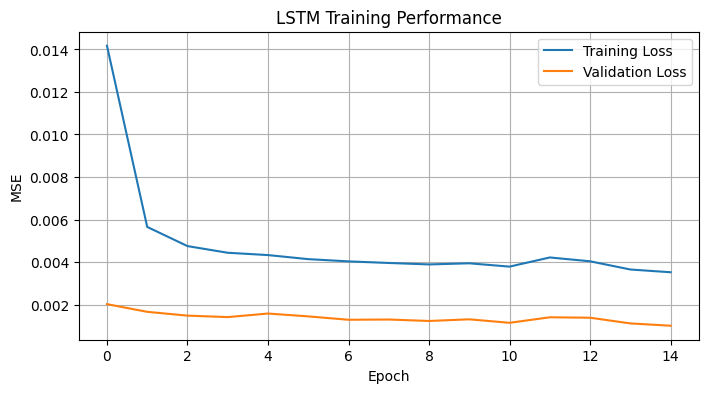

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("LSTM Training Performance")
plt.legend()
plt.grid()
plt.show()

In [ ]:
pred_scaled = model.predict(X_test, verbose=0)

y_actual = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

y_pred = target_scaler.inverse_transform(
    pred_scaled
).flatten()

print("Predictions completed!")

Predictions completed!


In [ ]:
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print(f"MAE  : {mae:.4f} kW")
print(f"RMSE : {rmse:.4f} kW")

MAE  : 0.5974 kW
RMSE : 0.7794 kW


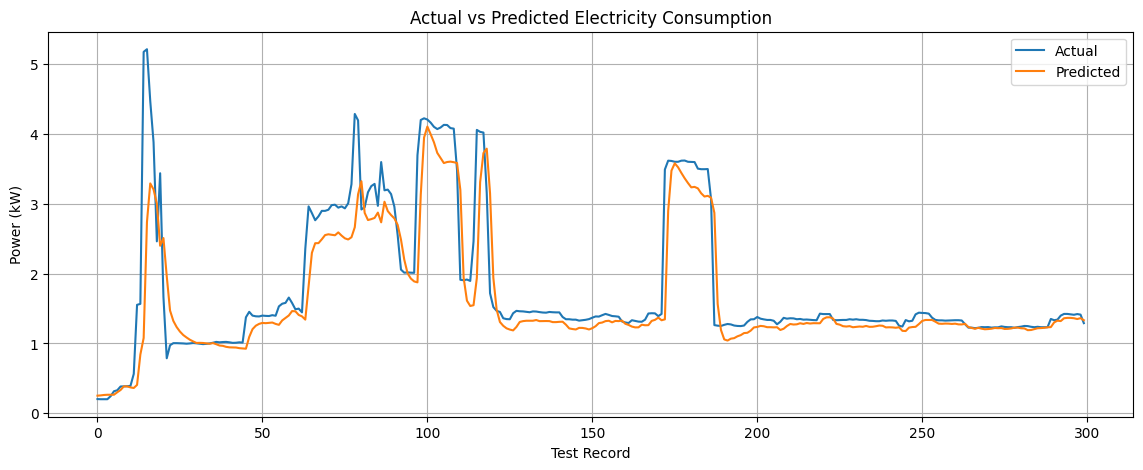

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(y_actual[:300], label="Actual")
plt.plot(y_pred[:300], label="Predicted")

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Test Record")
plt.ylabel("Power (kW)")
plt.legend()
plt.grid()
plt.show()

In [ ]:
results = pd.DataFrame({
    "Actual_kW": y_actual,
    "Predicted_kW": y_pred
})

results["Absolute_Error"] = abs(
    results["Actual_kW"] - results["Predicted_kW"]
)

display(results.head(20).round(4))

,Actual_kW,Predicted_kW,Absolute_Error
0,0.204,0.2529,0.0489
1,0.202,0.2568,0.0548
2,0.202,0.2629,0.0609
3,0.202,0.2658,0.0638
4,0.246,0.2655,0.0195
5,0.316,0.2664,0.0496
6,0.330,0.3017,0.0283
7,0.384,0.3336,0.0504
8,0.386,0.3858,0.0002
9,0.388,0.3852,0.0028


In [ ]:
latest_sequence = scaled_features[-LOOKBACK:]
latest_sequence = latest_sequence.reshape(
    1, LOOKBACK, len(features)
)

next_scaled = model.predict(latest_sequence, verbose=0)

next_consumption = target_scaler.inverse_transform(
    next_scaled
)[0, 0]

print(f"Next-minute predicted consumption: {next_consumption:.4f} kW")

Next-minute predicted consumption: 3.8969 kW


In [ ]:
print("HOUSEHOLD ELECTRICITY FORECASTING")
print("---------------------------------")
print("Model: LSTM")
print("Records:", len(data))
print("Lookback:", LOOKBACK, "minutes")
print(f"MAE: {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")
print(f"Next-minute forecast: {next_consumption:.4f} kW")

HOUSEHOLD ELECTRICITY FORECASTING
---------------------------------
Model: LSTM
Records: 10000
Lookback: 60 minutes
MAE: 0.5974 kW
RMSE: 0.7794 kW
Next-minute forecast: 3.8969 kW


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
r2 = r2_score(y_actual, y_pred)

print("MODEL PERFORMANCE")
print("------------------")
print(f"MAE  : {mae:.4f} kW")
print(f"RMSE : {rmse:.4f} kW")
print(f"R2 Score : {r2:.4f}")
print(f"R2 Percentage : {r2 * 100:.2f}%")

MODEL PERFORMANCE
------------------
MAE  : 0.5974 kW
RMSE : 0.7794 kW
R2 Score : 0.6794
R2 Percentage : 67.94%


In [ ]:
from sklearn.metrics import mean_absolute_error
import numpy as np

mae = mean_absolute_error(y_actual, y_pred)

actual_mean = np.mean(np.abs(y_actual))

accuracy = (1 - mae / actual_mean) * 100

accuracy = max(0, accuracy)

print(f"Model Accuracy: {accuracy:.2f}%")

Model Accuracy: 75.54%


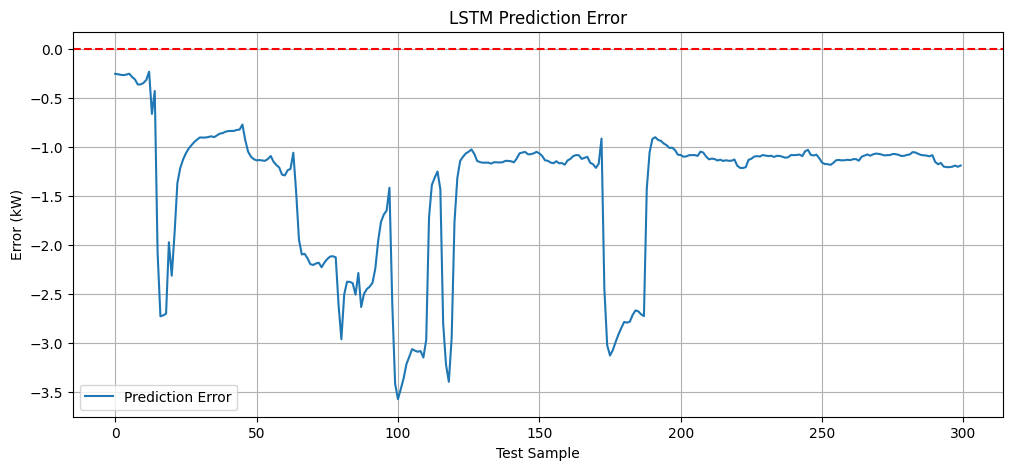

In [28]:
import numpy as np
import matplotlib.pyplot as plt

# Convert scaled values back to kW if needed
actual = y_test.reshape(-1)
predicted = y_pred.reshape(-1)

# Calculate prediction error
error = actual - predicted

# Plot error
plt.figure(figsize=(12, 5))
plt.plot(error[:300], label="Prediction Error")
plt.axhline(0, color="red", linestyle="--")
plt.title("LSTM Prediction Error")
plt.xlabel("Test Sample")
plt.ylabel("Error (kW)")
plt.legend()
plt.grid(True)
plt.show()